# Phase 3 - Flight Delay Data Analysis

**Course:** COMP4381 Data Science and Analytics  
**Project:** Flight Delay Prediction Around the World  
**Phase 3 Deliverable:** Data analysis notebook and report section

This notebook prepares and analyzes EUROCONTROL airport punctuality data together with airport metadata.  
The main goal in this phase is not to build the final machine learning model yet. The goal is to describe the dataset, clean it, preprocess it, summarize it, create visualizations, and explain the main findings.


## 1. Import libraries and set paths

We use basic Python data science libraries that are suitable for this stage: `pandas` for reading and preparing the data, and `matplotlib` for simple visualizations. The paths are written relative to the notebook location so the notebook can run from the GitHub repository without manual path changes.


In [1]:
from pathlib import Path
import pandas as pd
import matplotlib.pyplot as plt

# The notebook is inside notebooks/, so the project root is one level above it.
PROJECT_ROOT = Path.cwd().parent if Path.cwd().name == 'notebooks' else Path.cwd()
RAW_DIR = PROJECT_ROOT / 'data' / 'raw'
PROCESSED_DIR = PROJECT_ROOT / 'data' / 'processed'
FIGURES_DIR = PROJECT_ROOT / 'figures'

PROCESSED_DIR.mkdir(parents=True, exist_ok=True)
FIGURES_DIR.mkdir(parents=True, exist_ok=True)

print('Project root:', PROJECT_ROOT)
print('Raw data folder:', RAW_DIR)
print('Processed data folder:', PROCESSED_DIR)
print('Figures folder:', FIGURES_DIR)


Project root: /mnt/data/phase3_project
Raw data folder: /mnt/data/phase3_project/data/raw
Processed data folder: /mnt/data/phase3_project/data/processed
Figures folder: /mnt/data/phase3_project/figures


## 2. Load the raw data

The raw data folder contains EUROCONTROL Excel files and an `airports.csv` metadata file. The EUROCONTROL files contain airport-day punctuality records. The airport metadata file gives extra information such as country, airport type, location, elevation, and scheduled service flag.


In [2]:
eurocontrol_files = sorted(RAW_DIR.glob('eurocontrol_*.xlsx'))
airports_file = RAW_DIR / 'airports.csv'

print('EUROCONTROL files found:')
for file in eurocontrol_files:
    print('-', file.name)
print()
print('Airport metadata file exists:', airports_file.exists())


EUROCONTROL files found:
- eurocontrol_france.xlsx
- eurocontrol_germany.xlsx
- eurocontrol_italy.xlsx
- eurocontrol_spain.xlsx
- eurocontrol_sweden.xlsx

Airport metadata file exists: True


In [3]:
frames = []

for file in eurocontrol_files:
    temp = pd.read_excel(file, sheet_name='Data')
    temp['source_file'] = file.name
    frames.append(temp)

delay_raw = pd.concat(frames, ignore_index=True)
airports_raw = pd.read_csv(airports_file, low_memory=False)

print('Combined EUROCONTROL raw shape:', delay_raw.shape)
print('Airport metadata shape:', airports_raw.shape)

delay_raw.head()


Combined EUROCONTROL raw shape: (252455, 9)
Airport metadata shape: (85251, 24)


,Date,Airport,Departure Punctuality %,Arrival Punctuality %,Avg Departure Schedule Delay,Avg Arrival Schedule Delay,Avg Departure - Arrival Schedule Delay,Operated Schedules %,source_file
0,2022-01-01,Brussels,0.816327,0.776316,12.700680,12.238487,0.462193,0.896970,eurocontrol_france.xlsx
1,2022-01-02,Brussels,0.701923,0.698980,15.014423,16.865391,-1.850968,0.918103,eurocontrol_france.xlsx
2,2022-01-03,Brussels,0.721154,0.754717,12.394231,11.233884,1.160347,0.941441,eurocontrol_france.xlsx
3,2022-01-04,Brussels,0.807487,0.809524,15.807487,14.900088,0.907398,0.893023,eurocontrol_france.xlsx
4,2022-01-05,Brussels,0.878173,0.825871,9.416244,8.678358,0.737885,0.970732,eurocontrol_france.xlsx


## 3. Dataset description

The EUROCONTROL data is an airport-day dataset. This means that each row represents the punctuality situation of one airport on one date. It is not individual passenger data and it is not individual flight-level data.

Main columns from the punctuality dataset:

- `Date`: the day of the airport record.
- `Airport`: airport name as written in the EUROCONTROL file.
- `Departure Punctuality %`: percentage of departures that were punctual.
- `Arrival Punctuality %`: percentage of arrivals that were punctual.
- `Avg Departure Schedule Delay`: average departure delay in minutes.
- `Avg Arrival Schedule Delay`: average arrival delay in minutes.
- `Avg Departure - Arrival Schedule Delay`: difference between departure and arrival average delay.
- `Operated Schedules %`: percentage of planned schedules that actually operated.

The airport metadata file is used to add country and airport-level details.


In [4]:
print('EUROCONTROL columns:')
print(delay_raw.columns.tolist())

print()
print('Airport metadata columns:')
print(airports_raw.columns.tolist())


EUROCONTROL columns:
['Date', 'Airport', 'Departure Punctuality %', 'Arrival Punctuality %', 'Avg Departure Schedule Delay', 'Avg Arrival Schedule Delay', 'Avg Departure - Arrival Schedule Delay', 'Operated Schedules %', 'source_file']

Airport metadata columns:
['id', 'ident', 'type', 'name', 'latitude_deg', 'longitude_deg', 'elevation_ft', 'continent', 'country_name', 'iso_country', 'region_name', 'iso_region', 'local_region', 'municipality', 'scheduled_service', 'gps_code', 'icao_code', 'iata_code', 'local_code', 'home_link', 'wikipedia_link', 'keywords', 'score', 'last_updated']


## 4. Cleaning the raw data

The project files include several EUROCONTROL Excel files. In this cleaning step, we remove exact repeated rows after loading them. This prevents the same airport-day record from being counted more than once.


In [5]:
rows_before = len(delay_raw)

delay_clean = delay_raw.drop(columns=['source_file']).drop_duplicates().copy()
rows_after = len(delay_clean)

print('Rows before removing duplicates:', rows_before)
print('Rows after removing duplicates:', rows_after)
print('Removed duplicate rows:', rows_before - rows_after)


Rows before removing duplicates: 252455
Rows after removing duplicates: 50491
Removed duplicate rows: 201964


## 5. Select five countries and map airports

The project originally asks for at least five countries. The selected countries here are **France, Germany, Italy, Spain, and Sweden**. These countries are available inside the EUROCONTROL airport-day data.

The EUROCONTROL file gives airport names but not IATA codes directly, so a small mapping is created to connect each selected airport with the airport metadata file.


In [6]:
airport_code_map = {
    # Germany
    'Frankfurt': 'FRA',
    'Dusseldorf': 'DUS',
    'Munich': 'MUC',

    # Sweden
    'Stockholm Arlanda': 'ARN',

    # Spain
    'Barcelona': 'BCN',
    'Madrid Barajas': 'MAD',
    'Palma de Mallorca': 'PMI',

    # France
    'Nice': 'NCE',
    'Paris Charles de Gaulle': 'CDG',
    'Paris Orly': 'ORY',

    # Italy
    'Milan Malpensa': 'MXP',
    'Rome Fiumicino': 'FCO'
}

selected = delay_clean[delay_clean['Airport'].isin(airport_code_map.keys())].copy()
selected['iata_code'] = selected['Airport'].map(airport_code_map)

print('Selected shape before airport metadata merge:', selected.shape)
print('Selected airports:', selected['Airport'].nunique())
selected['Airport'].value_counts().sort_index()


Selected shape before airport metadata merge: (18935, 9)
Selected airports: 12


Airport
Barcelona                  1578
Dusseldorf                 1578
Frankfurt                  1578
Madrid Barajas             1578
Milan Malpensa             1578
Munich                     1577
Nice                       1578
Palma de Mallorca          1578
Paris Charles de Gaulle    1578
Paris Orly                 1578
Rome Fiumicino             1578
Stockholm Arlanda          1578
Name: count, dtype: int64

## 6. Merge with airport metadata

The airport metadata is joined using the IATA airport code. This adds country, municipality, airport type, latitude, longitude, elevation, and scheduled service information.


In [7]:
metadata_columns = [
    'iata_code', 'name', 'country_name', 'iso_country', 'region_name',
    'municipality', 'type', 'latitude_deg', 'longitude_deg',
    'elevation_ft', 'scheduled_service'
]

airports_meta = airports_raw[metadata_columns].copy()

merged = selected.merge(airports_meta, on='iata_code', how='left')

print('Merged shape:', merged.shape)
print('Missing airport metadata rows:', merged['name'].isna().sum())
merged.head()


Merged shape: (18935, 19)
Missing airport metadata rows: 0


,Date,Airport,Departure Punctuality %,Arrival Punctuality %,Avg Departure Schedule Delay,Avg Arrival Schedule Delay,Avg Departure - Arrival Schedule Delay,Operated Schedules %,iata_code,name,country_name,iso_country,region_name,municipality,type,latitude_deg,longitude_deg,elevation_ft,scheduled_service
0,2022-01-01,Frankfurt,0.818898,0.804217,13.043920,13.426908,-0.382988,0.922170,FRA,Frankfurt Main Airport,Germany,DE,Hesse,Frankfurt am Main,large_airport,50.026706,8.55835,364.0,1
1,2022-01-02,Frankfurt,0.707216,0.713389,17.652062,18.506590,-0.854528,0.946463,FRA,Frankfurt Main Airport,Germany,DE,Hesse,Frankfurt am Main,large_airport,50.026706,8.55835,364.0,1
2,2022-01-03,Frankfurt,0.738938,0.755991,16.235140,13.956209,2.278931,0.952183,FRA,Frankfurt Main Airport,Germany,DE,Hesse,Frankfurt am Main,large_airport,50.026706,8.55835,364.0,1
3,2022-01-04,Frankfurt,0.630542,0.725962,16.605624,14.621955,1.983669,0.953811,FRA,Frankfurt Main Airport,Germany,DE,Hesse,Frankfurt am Main,large_airport,50.026706,8.55835,364.0,1
4,2022-01-05,Frankfurt,0.782816,0.821951,10.382379,9.699187,0.683192,0.946785,FRA,Frankfurt Main Airport,Germany,DE,Hesse,Frankfurt am Main,large_airport,50.026706,8.55835,364.0,1


## 7. Preprocessing and feature engineering

In this step, we clean column names, fix the date type, and create new date-based and delay-based features. These features help the analysis and can also be useful later in Phase 4 for modeling.


In [8]:
df = merged.copy()

# Rename columns to simple snake_case names.
df = df.rename(columns={
    'Date': 'date',
    'Airport': 'airport',
    'Departure Punctuality %': 'departure_punctuality_pct',
    'Arrival Punctuality %': 'arrival_punctuality_pct',
    'Avg Departure Schedule Delay': 'avg_departure_delay_min',
    'Avg Arrival Schedule Delay': 'avg_arrival_delay_min',
    'Avg Departure - Arrival Schedule Delay': 'avg_departure_minus_arrival_delay_min',
    'Operated Schedules %': 'operated_schedules_pct',
    'name': 'airport_full_name',
    'country_name': 'country',
    'type': 'airport_type'
})

# Make sure date is a datetime column.
df['date'] = pd.to_datetime(df['date'])

# Date features.
df['year'] = df['date'].dt.year
df['month'] = df['date'].dt.month
df['month_name'] = df['date'].dt.month_name()
df['quarter'] = df['date'].dt.quarter
df['weekday'] = df['date'].dt.weekday
df['weekday_name'] = df['date'].dt.day_name()

# Season feature.
def get_season(month):
    if month in [12, 1, 2]:
        return 'Winter'
    if month in [3, 4, 5]:
        return 'Spring'
    if month in [6, 7, 8]:
        return 'Summer'
    return 'Autumn'

df['season'] = df['month'].apply(get_season)

# Future target ideas for Phase 4.
df['target_delayed'] = (df['avg_arrival_delay_min'] >= 15).astype(int)

def arrival_delay_category(delay):
    if delay < 5:
        return 'Low'
    if delay < 15:
        return 'Medium'
    return 'High'

df['arrival_delay_category'] = df['avg_arrival_delay_min'].apply(arrival_delay_category)

# Keep a clear column order.
ordered_columns = [
    'date', 'year', 'month', 'month_name', 'quarter', 'weekday', 'weekday_name', 'season',
    'airport', 'iata_code', 'airport_full_name', 'country', 'iso_country', 'region_name',
    'municipality', 'airport_type', 'latitude_deg', 'longitude_deg', 'elevation_ft',
    'scheduled_service', 'departure_punctuality_pct', 'arrival_punctuality_pct',
    'avg_departure_delay_min', 'avg_arrival_delay_min',
    'avg_departure_minus_arrival_delay_min', 'operated_schedules_pct',
    'target_delayed', 'arrival_delay_category'
]

df = df[ordered_columns]

print('Final cleaned dataset shape:', df.shape)
df.head()


Final cleaned dataset shape: (18935, 28)


,date,year,month,month_name,quarter,weekday,weekday_name,season,airport,iata_code,airport_full_name,country,iso_country,region_name,municipality,airport_type,latitude_deg,longitude_deg,elevation_ft,scheduled_service,departure_punctuality_pct,arrival_punctuality_pct,avg_departure_delay_min,avg_arrival_delay_min,avg_departure_minus_arrival_delay_min,operated_schedules_pct,target_delayed,arrival_delay_category
0,2022-01-01,2022,1,January,1,5,Saturday,Winter,Frankfurt,FRA,Frankfurt Main Airport,Germany,DE,Hesse,Frankfurt am Main,large_airport,50.026706,8.55835,364.0,1,0.818898,0.804217,13.043920,13.426908,-0.382988,0.922170,0,Medium
1,2022-01-02,2022,1,January,1,6,Sunday,Winter,Frankfurt,FRA,Frankfurt Main Airport,Germany,DE,Hesse,Frankfurt am Main,large_airport,50.026706,8.55835,364.0,1,0.707216,0.713389,17.652062,18.506590,-0.854528,0.946463,1,High
2,2022-01-03,2022,1,January,1,0,Monday,Winter,Frankfurt,FRA,Frankfurt Main Airport,Germany,DE,Hesse,Frankfurt am Main,large_airport,50.026706,8.55835,364.0,1,0.738938,0.755991,16.235140,13.956209,2.278931,0.952183,0,Medium
3,2022-01-04,2022,1,January,1,1,Tuesday,Winter,Frankfurt,FRA,Frankfurt Main Airport,Germany,DE,Hesse,Frankfurt am Main,large_airport,50.026706,8.55835,364.0,1,0.630542,0.725962,16.605624,14.621955,1.983669,0.953811,0,Medium
4,2022-01-05,2022,1,January,1,2,Wednesday,Winter,Frankfurt,FRA,Frankfurt Main Airport,Germany,DE,Hesse,Frankfurt am Main,large_airport,50.026706,8.55835,364.0,1,0.782816,0.821951,10.382379,9.699187,0.683192,0.946785,0,Medium


## 8. Check missing values and save the cleaned data

Before saving the cleaned dataset, we check missing values and basic dataset size. The cleaned file is saved inside `data/processed` so it can be reused in the next phase.


In [9]:
print('Rows:', df.shape[0])
print('Columns:', df.shape[1])
print('Countries:', df['country'].nunique())
print('Airports:', df['airport'].nunique())
print('Date range:', df['date'].min().date(), 'to', df['date'].max().date())

missing_summary = df.isna().sum().sort_values(ascending=False)
missing_summary[missing_summary > 0]


Rows: 18935
Columns: 28
Countries: 5
Airports: 12
Date range: 2022-01-01 to 2026-04-27


Series([], dtype: int64)

In [10]:
processed_path = PROCESSED_DIR / 'cleaned_flight_delay_data.csv'
df.to_csv(processed_path, index=False)
print('Saved cleaned dataset to:', processed_path)


Saved cleaned dataset to: /mnt/data/phase3_project/data/processed/cleaned_flight_delay_data.csv


## 9. Data summarization

Now we summarize the cleaned dataset. This helps us understand the size of the data, the selected countries, and the main delay values before making charts.


In [11]:
summary_table = pd.DataFrame({
    'Metric': [
        'Rows', 'Columns', 'Countries', 'Airports',
        'Start date', 'End date',
        'Mean arrival delay minutes', 'Median arrival delay minutes',
        'Mean departure delay minutes', 'Median departure delay minutes'
    ],
    'Value': [
        df.shape[0], df.shape[1], df['country'].nunique(), df['airport'].nunique(),
        df['date'].min().date(), df['date'].max().date(),
        round(df['avg_arrival_delay_min'].mean(), 2),
        round(df['avg_arrival_delay_min'].median(), 2),
        round(df['avg_departure_delay_min'].mean(), 2),
        round(df['avg_departure_delay_min'].median(), 2)
    ]
})
summary_table


,Metric,Value
0,Rows,18935
1,Columns,28
2,Countries,5
3,Airports,12
4,Start date,2022-01-01
5,End date,2026-04-27
6,Mean arrival delay minutes,13.59
7,Median arrival delay minutes,11.97
8,Mean departure delay minutes,17.71
9,Median departure delay minutes,15.85


In [12]:
country_summary = df.groupby('country').agg(
    rows=('country', 'size'),
    airports=('airport', 'nunique'),
    mean_arrival_delay=('avg_arrival_delay_min', 'mean'),
    median_arrival_delay=('avg_arrival_delay_min', 'median'),
    mean_departure_delay=('avg_departure_delay_min', 'mean'),
    mean_arrival_punctuality=('arrival_punctuality_pct', 'mean'),
    mean_operated_schedules=('operated_schedules_pct', 'mean')
).round(3).sort_values('mean_arrival_delay', ascending=False)

country_summary


,rows,airports,mean_arrival_delay,median_arrival_delay,mean_departure_delay,mean_arrival_punctuality,mean_operated_schedules
country,,,,,,,
Italy,3156,2,14.851,13.365,19.940,0.749,0.959
France,4734,3,13.889,12.311,19.349,0.749,0.928
Germany,4733,3,13.500,12.012,17.914,0.756,0.951
Spain,4734,3,13.060,11.248,16.499,0.779,0.948
Sweden,1578,1,11.986,10.393,11.328,0.781,0.959


In [13]:
airport_summary = df.groupby(['country', 'airport']).agg(
    rows=('airport', 'size'),
    mean_arrival_delay=('avg_arrival_delay_min', 'mean'),
    mean_departure_delay=('avg_departure_delay_min', 'mean'),
    mean_arrival_punctuality=('arrival_punctuality_pct', 'mean'),
    mean_operated_schedules=('operated_schedules_pct', 'mean')
).round(3).sort_values('mean_arrival_delay', ascending=False)

airport_summary.head(12)


rows  ...  mean_operated_schedules
country airport                        ...                         
Italy   Milan Malpensa           1578  ...                    0.949
Germany Frankfurt                1578  ...                    0.948
France  Nice                     1578  ...                    0.880
        Paris Charles de Gaulle  1578  ...                    0.958
Spain   Barcelona                1578  ...                    0.960
        Palma de Mallorca        1578  ...                    0.938
Germany Dusseldorf               1578  ...                    0.952
Italy   Rome Fiumicino           1578  ...                    0.969
France  Paris Orly               1578  ...                    0.945
Germany Munich                   1577  ...                    0.954
Sweden  Stockholm Arlanda        1578  ...                    0.959
Spain   Madrid Barajas           1578  ...                    0.945

[12 rows x 5 columns]

## 10. Visualizations and interpretation

The following charts show the main patterns in the data. Each chart is followed by a short interpretation.


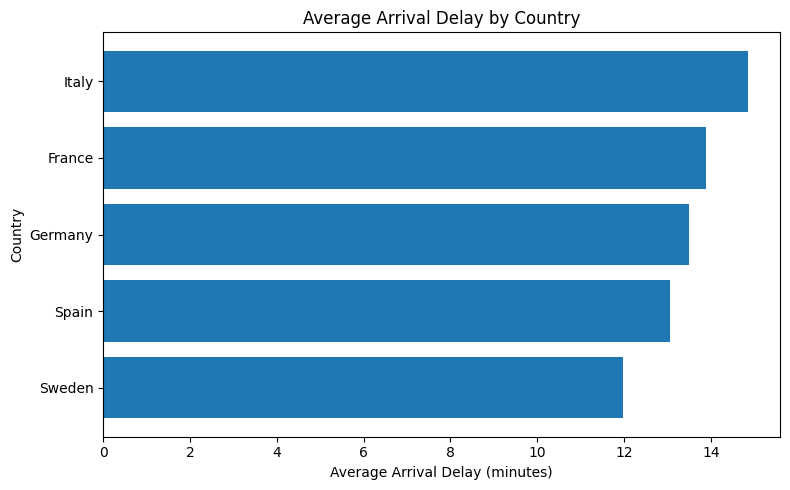

In [14]:
# Chart 1: Average arrival delay by country.
chart1 = country_summary.sort_values('mean_arrival_delay', ascending=True)

plt.figure(figsize=(8, 5))
plt.barh(chart1.index, chart1['mean_arrival_delay'])
plt.xlabel('Average Arrival Delay (minutes)')
plt.ylabel('Country')
plt.title('Average Arrival Delay by Country')
plt.tight_layout()
plt.savefig(FIGURES_DIR / 'avg_arrival_delay_by_country.png', dpi=150)
plt.show()


**Interpretation:** This chart compares the selected countries by average arrival delay. Countries with longer bars had higher average arrival delay in the selected airport-day records. This does not prove the country itself is the cause, because the result may also depend on airport size, time period, traffic, weather, and how the data is aggregated.


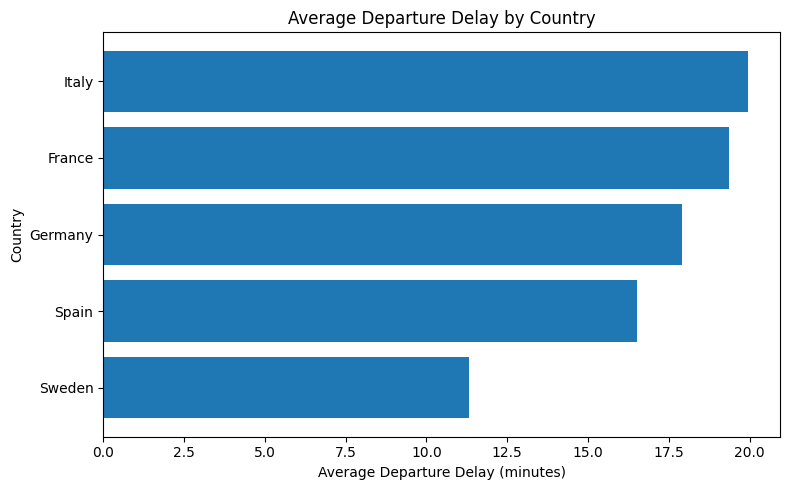

In [15]:
# Chart 2: Average departure delay by country.
chart2 = country_summary.sort_values('mean_departure_delay', ascending=True)

plt.figure(figsize=(8, 5))
plt.barh(chart2.index, chart2['mean_departure_delay'])
plt.xlabel('Average Departure Delay (minutes)')
plt.ylabel('Country')
plt.title('Average Departure Delay by Country')
plt.tight_layout()
plt.savefig(FIGURES_DIR / 'avg_departure_delay_by_country.png', dpi=150)
plt.show()


**Interpretation:** Departure delay is important because it can spread to later flights. If departure delay is high in some countries or airports, this may point to congestion, operational problems, or external conditions that affected schedules.


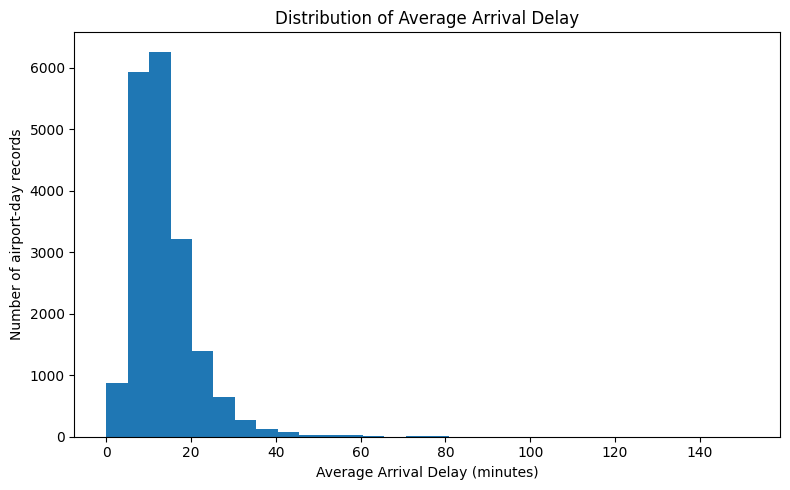

In [16]:
# Chart 3: Distribution of arrival delay minutes.
plt.figure(figsize=(8, 5))
plt.hist(df['avg_arrival_delay_min'], bins=30)
plt.xlabel('Average Arrival Delay (minutes)')
plt.ylabel('Number of airport-day records')
plt.title('Distribution of Average Arrival Delay')
plt.tight_layout()
plt.savefig(FIGURES_DIR / 'arrival_delay_distribution.png', dpi=150)
plt.show()


**Interpretation:** The histogram shows how the arrival delay values are distributed. Most records are usually close to the normal delay range, while a smaller number of airport-day records have much larger delay values. These large values can affect the mean, so the median is also useful.


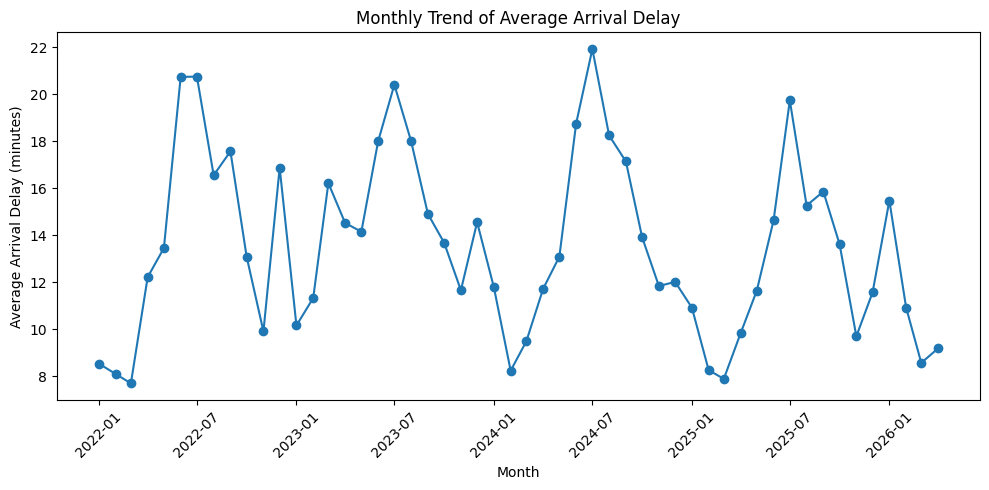

In [17]:
# Chart 4: Monthly trend of arrival delay.
monthly_trend = df.groupby(['year', 'month']).agg(
    mean_arrival_delay=('avg_arrival_delay_min', 'mean')
).reset_index()
monthly_trend['year_month'] = pd.to_datetime(monthly_trend[['year', 'month']].assign(day=1))

plt.figure(figsize=(10, 5))
plt.plot(monthly_trend['year_month'], monthly_trend['mean_arrival_delay'], marker='o')
plt.xlabel('Month')
plt.ylabel('Average Arrival Delay (minutes)')
plt.title('Monthly Trend of Average Arrival Delay')
plt.xticks(rotation=45)
plt.tight_layout()
plt.savefig(FIGURES_DIR / 'monthly_arrival_delay_trend.png', dpi=150)
plt.show()


**Interpretation:** The line chart helps show whether delay changes over time. Some months may have higher average delay because of seasonal travel, weather, airport traffic, or special events. This is why date-based features such as month and season are useful.


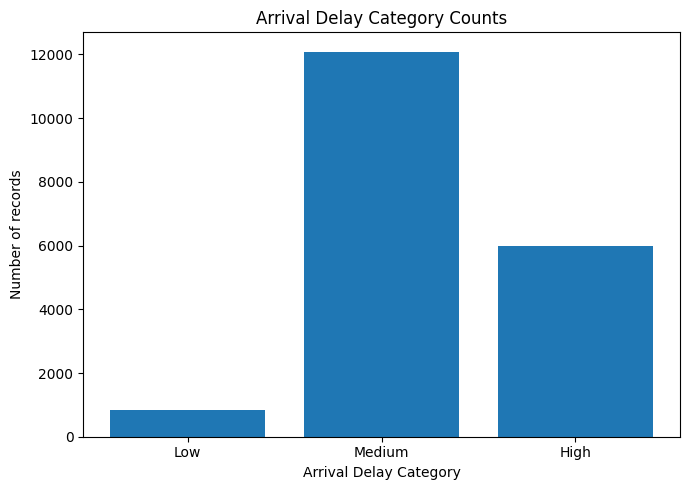

In [18]:
# Chart 5: Delay category counts.
category_counts = df['arrival_delay_category'].value_counts().reindex(['Low', 'Medium', 'High'])

plt.figure(figsize=(7, 5))
plt.bar(category_counts.index, category_counts.values)
plt.xlabel('Arrival Delay Category')
plt.ylabel('Number of records')
plt.title('Arrival Delay Category Counts')
plt.tight_layout()
plt.savefig(FIGURES_DIR / 'arrival_delay_category_counts.png', dpi=150)
plt.show()


**Interpretation:** The delay category chart is a simple way to prepare a possible classification target for Phase 4. A record is marked as high delay when its average arrival delay is 15 minutes or more.


In [19]:
# Correlation between numerical variables.
numeric_cols = [
    'latitude_deg', 'longitude_deg', 'elevation_ft',
    'departure_punctuality_pct', 'arrival_punctuality_pct',
    'avg_departure_delay_min', 'avg_arrival_delay_min',
    'avg_departure_minus_arrival_delay_min', 'operated_schedules_pct',
    'month', 'weekday'
]

correlation = df[numeric_cols].corr().round(3)
correlation


,latitude_deg,longitude_deg,elevation_ft,departure_punctuality_pct,arrival_punctuality_pct,avg_departure_delay_min,avg_arrival_delay_min,avg_departure_minus_arrival_delay_min,operated_schedules_pct,month,weekday
latitude_deg,1.000,0.621,-0.136,0.080,-0.007,-0.102,-0.028,-0.194,0.099,-0.000,-0.000
longitude_deg,0.621,1.000,-0.285,0.065,-0.028,-0.064,0.001,-0.157,0.070,-0.000,-0.000
elevation_ft,-0.136,-0.285,1.000,-0.005,0.058,-0.008,-0.048,0.074,0.046,-0.000,-0.000
departure_punctuality_pct,0.080,0.065,-0.005,1.000,0.884,-0.909,-0.804,-0.658,0.151,-0.243,-0.105
arrival_punctuality_pct,-0.007,-0.028,0.058,0.884,1.000,-0.872,-0.919,-0.345,0.208,-0.212,-0.115
avg_departure_delay_min,-0.102,-0.064,-0.008,-0.909,-0.872,1.000,0.921,0.654,-0.257,0.199,0.097
avg_arrival_delay_min,-0.028,0.001,-0.048,-0.804,-0.919,0.921,1.000,0.306,-0.266,0.175,0.104
avg_departure_minus_arrival_delay_min,-0.194,-0.157,0.074,-0.658,-0.345,0.654,0.306,1.000,-0.112,0.147,0.034
operated_schedules_pct,0.099,0.070,0.046,0.151,0.208,-0.257,-0.266,-0.112,1.000,0.060,0.021
month,-0.000,-0.000,-0.000,-0.243,-0.212,0.199,0.175,0.147,0.060,1.000,0.001


**Interpretation:** Correlation helps show simple numerical relationships. For example, arrival punctuality should usually have a negative relationship with average arrival delay, because better punctuality means lower delay. Correlation is only a simple statistical relationship and does not prove causation.


## 11. Main findings for the report section

- The cleaned analytical dataset contains more than 1,000 rows and more than 15 meaningful features.
- The selected data covers five countries: France, Germany, Italy, Spain, and Sweden.
- The row unit is airport-day, meaning each row describes one airport on one date.
- The dataset includes punctuality values, average delay minutes, operated schedules percentage, airport metadata, and date-based features.
- A future prediction target can be `target_delayed` or `arrival_delay_category`.
- Some limitations remain because the dataset is aggregated by airport-day and does not include individual flight-level causes or full weather information.
